In [122]:
import pickle
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

from matplotlib.colors import CenteredNorm
import scipy.stats as scis
# from scipy.stats import norm
from cmfa.emu_example import ordered_ilr_func, closure


In [123]:
RESULTS_DIR = Path("..") / "data" / "results" / "toy_example"
PLOT_DIR = Path("..") / "figures"

In [124]:
true_flux = np.load(RESULTS_DIR / "true_flux.npy")
true_id = np.load(RESULTS_DIR / "true_composition.npy")
print(f"True flux: {true_flux}")
print(f"True isotopologue distribution: {true_id}")


True flux: [100. 110.  50.  20.  20.  80.]
True isotopologue distribution: [6.34920635e-05 8.00761905e-01 1.98285714e-01 8.88888889e-04]


We start with analysis of the reference flux set from Antoniwitch 

In [125]:
intensity_msts = jnp.load(RESULTS_DIR / "intensity_measurements_reference.npy")
simulated_id = jnp.load(RESULTS_DIR / "id_simulated_reference.npy")

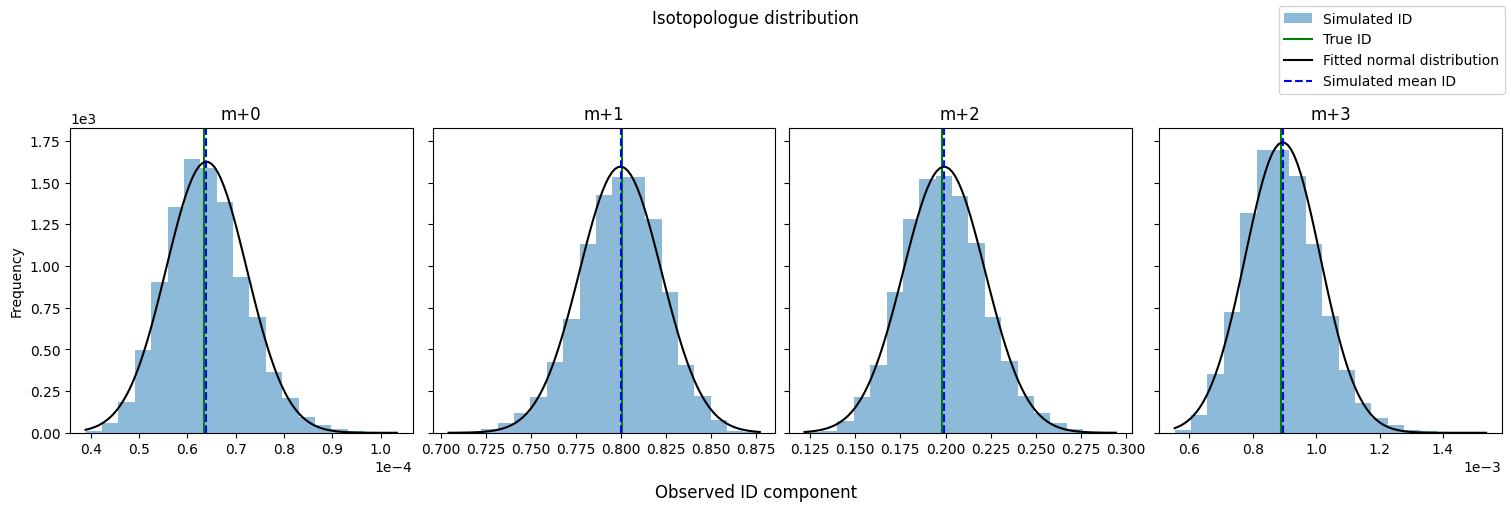

In [10]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True, layout='constrained')

for (i, ax) in enumerate(axes):
    simulated_id_i = simulated_id[:,i].flatten()
    xmin = np.min(simulated_id_i)
    xmax = np.max(simulated_id_i)
    bins = np.linspace(xmin, xmax, 20)
    bin_width = bins[1] - bins[0]
    h_trad = ax.hist(
        simulated_id_i, 
        bins=bins,
        alpha=0.5,
        label=f"Simulated ID",
    )
    ax.set(title=f"m+{i}")
    ax.axvline(true_id[i], label="True ID", color="green")
    mu, std = scis.norm.fit(simulated_id_i)
    x = np.linspace(xmin, xmax, 100)
    p = scis.norm.pdf(x, mu, std)
    scaled_p = p * len(simulated_id_i) * bin_width
    ax.plot(x, scaled_p, "k", label="Fitted normal distribution")
    ax.axvline(mu, label="Simulated mean ID", color="blue", linestyle="--")
    ax.ticklabel_format(scilimits=(-2,3))
    # ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
h,l = ax.get_legend_handles_labels()
f.supxlabel("Observed ID component")
f.legend(labels=l, loc="outside upper right")
f.suptitle("Isotopologue distribution");
f.savefig(PLOT_DIR / "simulated_id_toy.png", bbox_inches="tight", dpi=200)


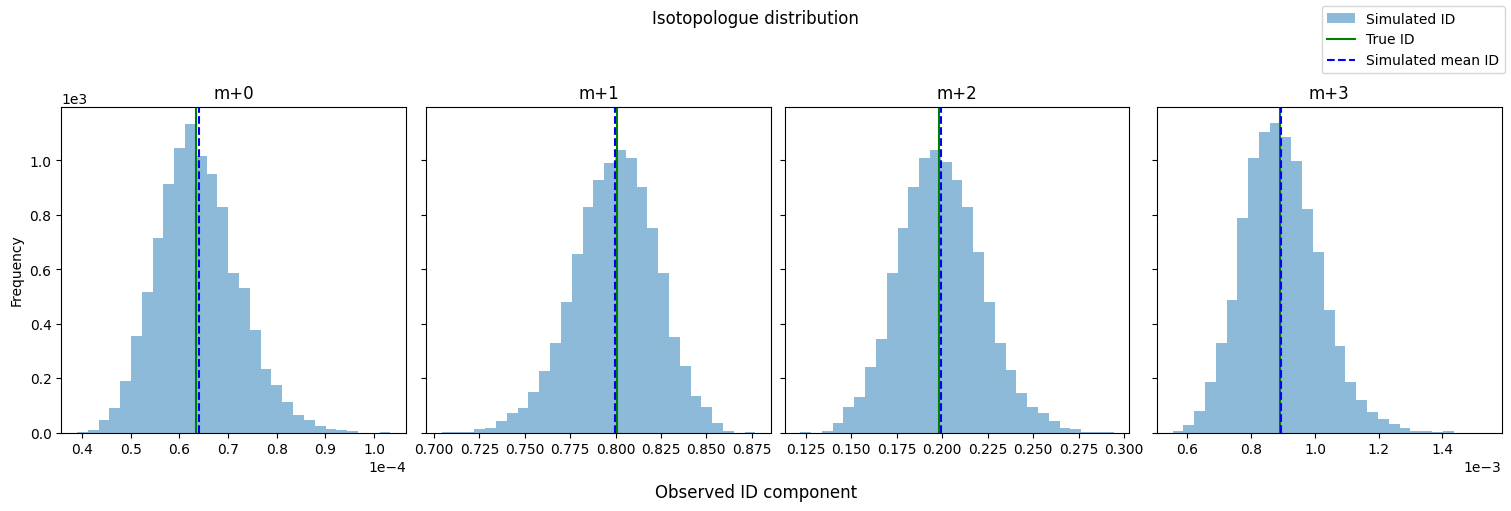

In [11]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True, layout='constrained')

for (i, ax) in enumerate(axes):
    simulated_id_i = simulated_id[:,i].flatten()
    xmin = np.min(simulated_id_i)
    xmax = np.max(simulated_id_i)
    bins = np.linspace(xmin, xmax, 30)
    bin_width = bins[1] - bins[0]
    h_trad = ax.hist(
        simulated_id_i, 
        bins=bins,
        alpha=0.5,
        label=f"Simulated ID",
    )
    ax.set(title=f"m+{i}")
    ax.axvline(true_id[i], label="True ID", color="green")
    mu, std = scis.norm.fit(simulated_id_i)
    x = np.linspace(xmin, xmax, 100)
    p = scis.norm.pdf(x, mu, std)
    scaled_p = p * len(simulated_id_i) * bin_width
    # ax.plot(x, scaled_p, "k", label="Fitted normal distribution")
    ax.axvline(mu, label="Simulated mean ID", color="blue", linestyle="--")
    ax.ticklabel_format(scilimits=(-2,3))
    # ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
h,l = ax.get_legend_handles_labels()
f.supxlabel("Observed ID component")
f.legend(labels=l, loc="outside upper right")
f.suptitle("Isotopologue distribution");
f.savefig(PLOT_DIR / "simulated_id_toy.png", bbox_inches="tight", dpi=200)


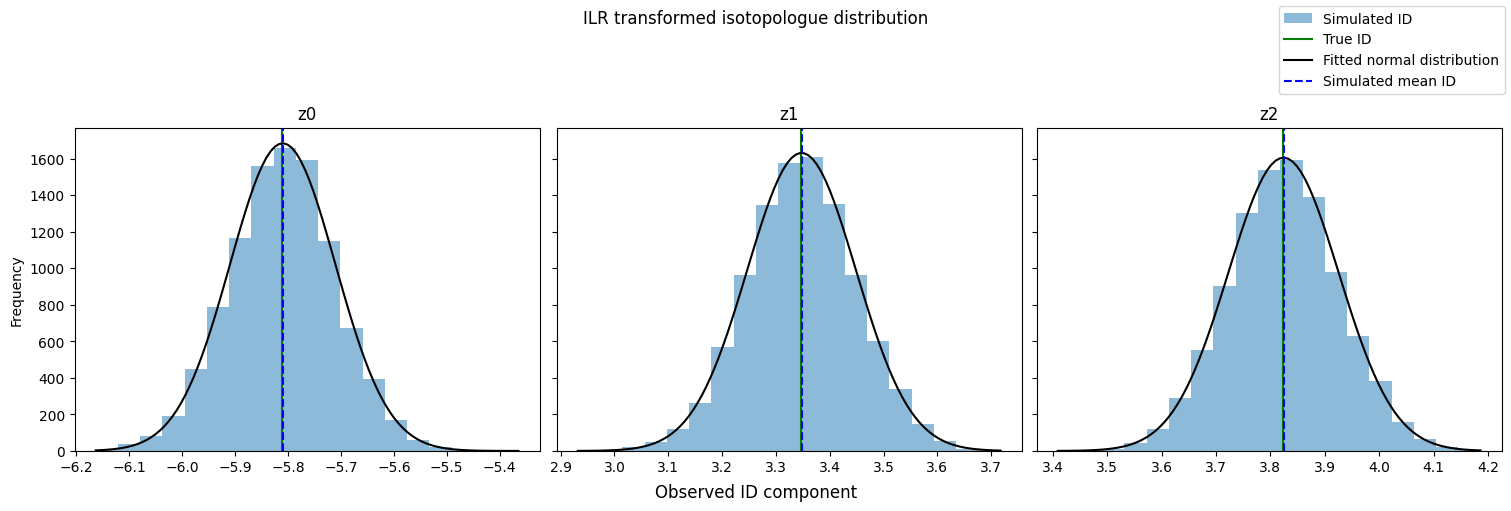

In [12]:
ilr_id_msts_true = ordered_ilr_func(simulated_id)
true_ilr_id = ordered_ilr_func(true_id)
f, axes = plt.subplots(1, 3, figsize=[15, 5], sharey=True, layout="constrained")

for (i, ax) in enumerate(axes):
    ilr_id_i = ilr_id_msts_true[:,i].flatten()
    xmin = np.min(ilr_id_i)
    xmax = np.max(ilr_id_i)
    bins = np.linspace(xmin, xmax, 20)
    bin_width = bins[1] - bins[0]
    h_trad = ax.hist(
        ilr_id_i, 
        bins=bins,
        alpha=0.5,
        label=f"Simulated ID" 
    )
    ax.set(title=f"z{i}")
    ax.axvline(true_ilr_id[i], label="True ID", color="green")
    mu, std = scis.norm.fit(ilr_id_i)
    x = np.linspace(xmin, xmax, 100)
    p = scis.norm.pdf(x, mu, std)
    scaled_p = p * len(ilr_id_i) * bin_width
    ax.plot(x, scaled_p, "k", label="Fitted normal distribution")
    ax.axvline(mu, label="Simulated mean ID", color="blue", linestyle="--")
    # ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
h,l = ax.get_legend_handles_labels()
f.supxlabel("Observed ID component")
f.legend(labels=l, loc="outside upper right")
f.suptitle("ILR transformed isotopologue distribution");
f.savefig(PLOT_DIR / "simulated_ilr_toy.png", bbox_inches="tight", dpi=200)

In [13]:
with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_ref = pickle.load(f)
estimated_fluxes_ref["trad"].shape

(10000, 6)

In [14]:
with open(RESULTS_DIR / "estimated_ids_reference.pkl", "rb") as f:
    estimated_ids_ref = pickle.load(f)
estimated_ids_ref["trad"].shape

(10000, 4)

In [15]:
resid_trad = (true_flux[None, [2, 4]] - estimated_fluxes_ref["trad"][:, [4,5]])
resid_clr = (true_flux[None, [2, 4]] - estimated_fluxes_ref["clr"][:, [4,5]])
resid_ilr = (true_flux[None, [2, 4]] - estimated_fluxes_ref["ilr"][:, [4,5]])

mse_trad = (resid_trad ** 2).mean(axis=(0))
mse_clr = (resid_clr ** 2).mean(axis=(0))
mse_ilr = (resid_ilr ** 2).mean(axis=(0))

mse_trad, mse_clr, mse_ilr

(Array([181.12988195,   2.87196816], dtype=float64),
 Array([142.17026363,   2.84658239], dtype=float64),
 Array([142.1706451 ,   2.84664011], dtype=float64))

In [16]:
id_resid_trad = (estimated_ids_ref["trad"] - true_id)
id_resid_clr = (estimated_ids_ref["clr"] - true_id)
id_resid_ilr = (estimated_ids_ref["ilr"] - true_id)

id_mse_trad = (id_resid_trad ** 2).mean(axis=(0))
id_mse_clr = (id_resid_clr ** 2).mean(axis=(0))
id_mse_ilr = (id_resid_ilr ** 2).mean(axis=(0))

id_mse_trad, id_mse_clr, id_mse_ilr

(Array([1.21515366e-10, 5.17115542e-04, 5.15180950e-04, 1.16571362e-08],      dtype=float64),
 Array([6.11304725e-11, 4.98401325e-04, 4.95870011e-04, 7.64706917e-09],      dtype=float64),
 Array([6.11249932e-11, 4.98412060e-04, 4.95880656e-04, 7.64672549e-09],      dtype=float64))

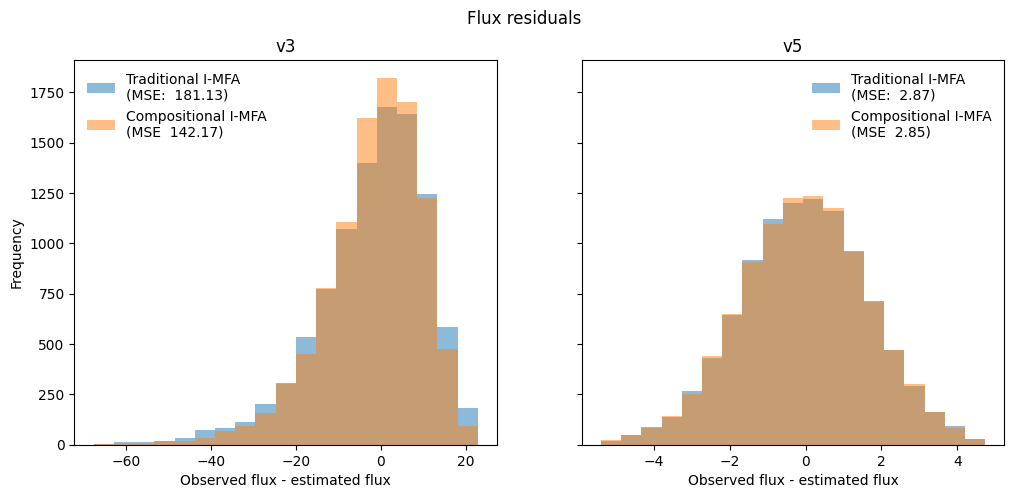

In [17]:
f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, i].flatten()
    resid_comp_i = resid_ilr[:, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 20)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2f})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2f})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{3+2*i}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_toy_true.png", bbox_inches="tight", dpi=200)

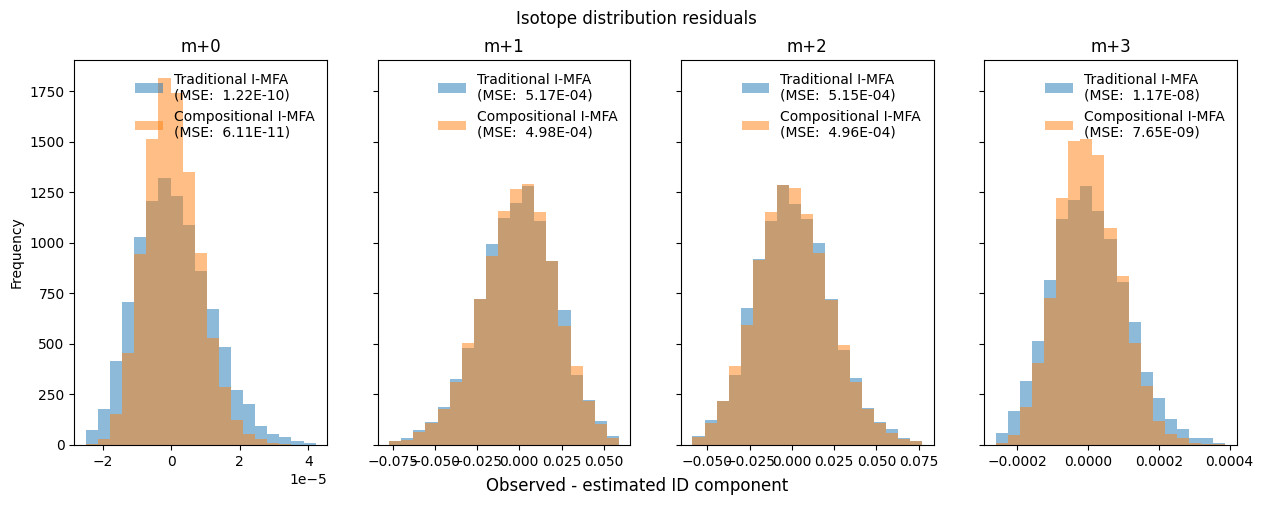

In [18]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = id_resid_trad[:, i].flatten()
    resid_comp_i = id_resid_ilr[:, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 20)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {id_mse_trad[i]: .2E})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE: {id_mse_ilr[i]: .2E})" 
    )
    ax.set(title=f"m+{i}")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
f.supxlabel("Observed - estimated ID component")

f.suptitle("Isotope distribution residuals");
f.savefig(PLOT_DIR / "id_residuals_toy_true.png", bbox_inches="tight", dpi=200)

In [19]:
with open(RESULTS_DIR / "estimated_fluxes_ci_reference.pkl", "rb") as f:
    estimated_fluxes_ci_reference = pickle.load(f)
estimated_fluxes_ci_reference["trad"].shape
flux_ci_trad = jnp.exp(jnp.log(estimated_fluxes_ci_reference["trad"][:,:,:]).mean(axis=0))
flux_ci_ilr = jnp.exp(jnp.log(estimated_fluxes_ci_reference["ilr"][:,:,:]).mean(axis=0))

In [20]:
flux = ["v2", "v4", "v6", "v1", "v3", "v5"]
print(f"{'Traditional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_trad):
    # :15.4f means 15 characters total width, 4 decimal places, as a float
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

               Traditional                
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v2     |          0.0147 |     839228.8815
v4     |          3.5753 |        111.4915
v6     |         14.3161 |        446.4333
v1     |        100.0000 |        100.0000
v3     |          0.0003 |    7408440.4762
v5     |          3.5753 |        111.4915


In [21]:
print(f"{'Compositional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_ilr):
    # :15.4f means 15 characters total width, 4 decimal places, as a float
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

              Compositional               
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v2     |         21.2000 |        578.4511
v4     |         13.7925 |         28.8847
v6     |         55.2475 |        115.7009
v1     |        100.0000 |        100.0000
v3     |         19.7210 |        129.4410
v5     |         13.7925 |         28.8847


# Sensitivity analysis

In [22]:
free_fluxes = jnp.load(RESULTS_DIR / "free_fluxes.npy")
free_fluxes.shape

(121, 2)

In [23]:
intensity_msts = jnp.load(RESULTS_DIR / "intensity_measurements.npy")
intensity_msts.shape

(121, 50, 4)

In [24]:
# id_msts_true = closure(intensity_msts[true_flux_index,:,:])

In [25]:
true_ids = jnp.load(RESULTS_DIR / "true_isotopologue_distributions.npy")

In [26]:
gini_indices= jnp.load(RESULTS_DIR / "gini_indices.npy")
entropies = jnp.load(RESULTS_DIR / "entropies.npy")

In [27]:
with open(RESULTS_DIR / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes = pickle.load(f)
estimated_fluxes["trad"].shape

(121, 50, 6)

In [28]:
with open(RESULTS_DIR / "hessian_matrices.pkl", "rb") as f:
    hessian_matrices = pickle.load(f)
hessian_matrices["trad"].shape

(121, 50, 2, 2)

In [29]:
with open(RESULTS_DIR / "estimated_ids.pkl", "rb") as f:
    estimated_ids = pickle.load(f)
estimated_ids["trad"].shape

(121, 50, 4)

In [30]:
resid_trad = (free_fluxes[:, None, :] - estimated_fluxes["trad"][:, :, [4, 5]])
resid_clr = (free_fluxes[:, None, :] - estimated_fluxes["clr"][:, :, [4, 5]])
resid_ilr = (free_fluxes[:, None, :] - estimated_fluxes["ilr"][:, :, [4, 5]])

mse_trad = (resid_trad ** 2).mean(axis=(0, 1))
mse_clr = (resid_clr ** 2).mean(axis=(0, 1))
mse_ilr = (resid_ilr ** 2).mean(axis=(0, 1))

mse_trad, mse_clr, mse_ilr

(Array([235.61323963,   2.6185388 ], dtype=float64),
 Array([176.35574838,   2.58495348], dtype=float64),
 Array([176.35023839,   2.58811078], dtype=float64))

In [31]:
resid_trad.shape

(121, 50, 2)

In [32]:
id_resid_trad = (estimated_ids["trad"] - true_ids[:, None, :])
id_resid_clr = (estimated_ids["clr"] - true_ids[:, None, :])
id_resid_ilr = (estimated_ids["ilr"] - true_ids[:, None, :])

id_mse_trad = (id_resid_trad ** 2).mean(axis=(0, 1))
id_mse_clr = (id_resid_clr ** 2).mean(axis=(0, 1))
id_mse_ilr = (id_resid_ilr ** 2).mean(axis=(0, 1))

id_mse_trad, id_mse_clr, id_mse_ilr

(Array([6.95082694e-10, 5.10826195e-04, 5.08370111e-04, 2.87924643e-08],      dtype=float64),
 Array([3.83722062e-10, 4.93279443e-04, 4.90043244e-04, 1.95565725e-08],      dtype=float64),
 Array([3.82809616e-10, 4.93772132e-04, 4.90520258e-04, 1.95529085e-08],      dtype=float64))

In [33]:
true_ilrs = ordered_ilr_func(true_ids)
trad_ilrs = ordered_ilr_func(estimated_ids["trad"])
clr_ilrs = ordered_ilr_func(estimated_ids["clr"])
ilr_ilrs = ordered_ilr_func(estimated_ids["ilr"])

ilr_resid_trad = trad_ilrs - true_ilrs[:, None, :]
ilr_resid_clr = clr_ilrs - true_ilrs[:, None, :]
ilr_resid_ilr = ilr_ilrs - true_ilrs[:, None, :]

ilr_mse_trad = (ilr_resid_trad ** 2).mean(axis=(0, 1))
ilr_mse_clr = (ilr_resid_clr ** 2).mean(axis=(0, 1))
ilr_mse_ilr = (ilr_resid_ilr ** 2).mean(axis=(0, 1))

ilr_mse_trad, ilr_mse_clr, ilr_mse_ilr

(Array([8.04913823, 1.33628525, 3.93150205], dtype=float64),
 Array([0.00636707, 0.00964308, 0.00410909], dtype=float64),
 Array([0.00634162, 0.00965924, 0.00408897], dtype=float64))

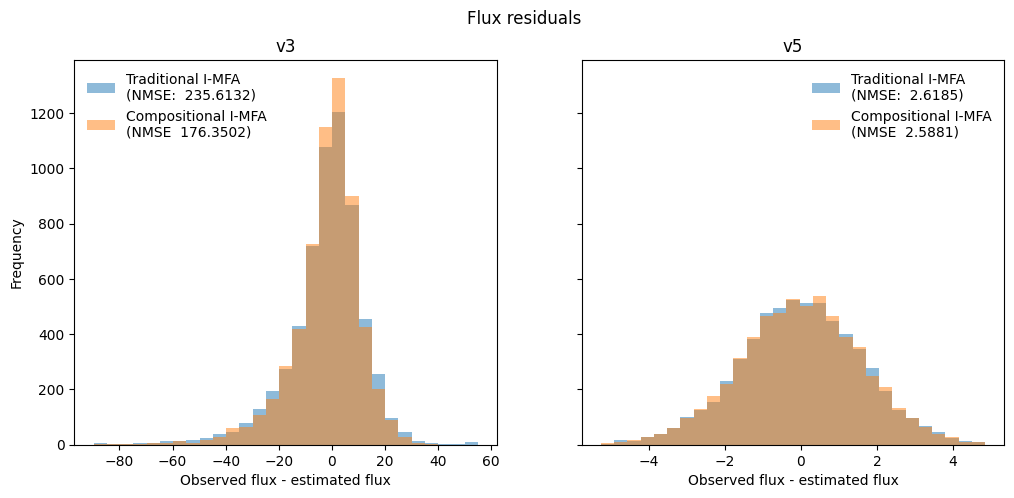

In [34]:
f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, :, i].flatten()
    resid_comp_i = resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(NMSE: {mse_trad[i]: .4f})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(NMSE {mse_ilr[i]: .4f})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{3+2*i}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_toy.png", bbox_inches="tight", dpi=200)

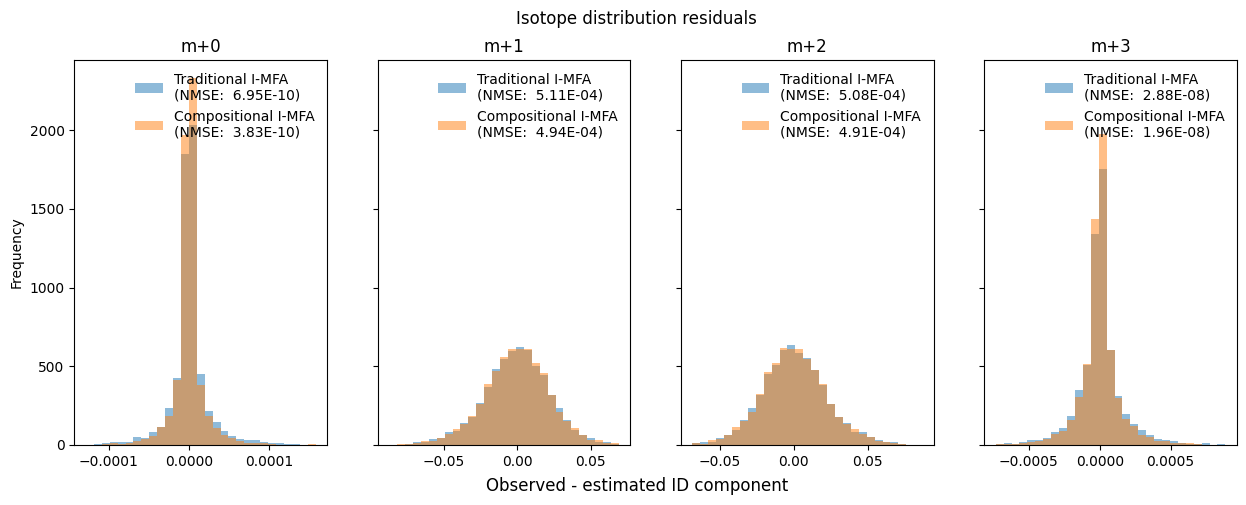

In [35]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = id_resid_trad[:, :, i].flatten()
    resid_comp_i = id_resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(NMSE: {id_mse_trad[i]: .2E})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(NMSE: {id_mse_ilr[i]: .2E})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"m+{i}")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
f.supxlabel("Observed - estimated ID component")

f.suptitle("Isotope distribution residuals");
f.savefig(PLOT_DIR / "id_residuals_toy.png", bbox_inches="tight", dpi=200)

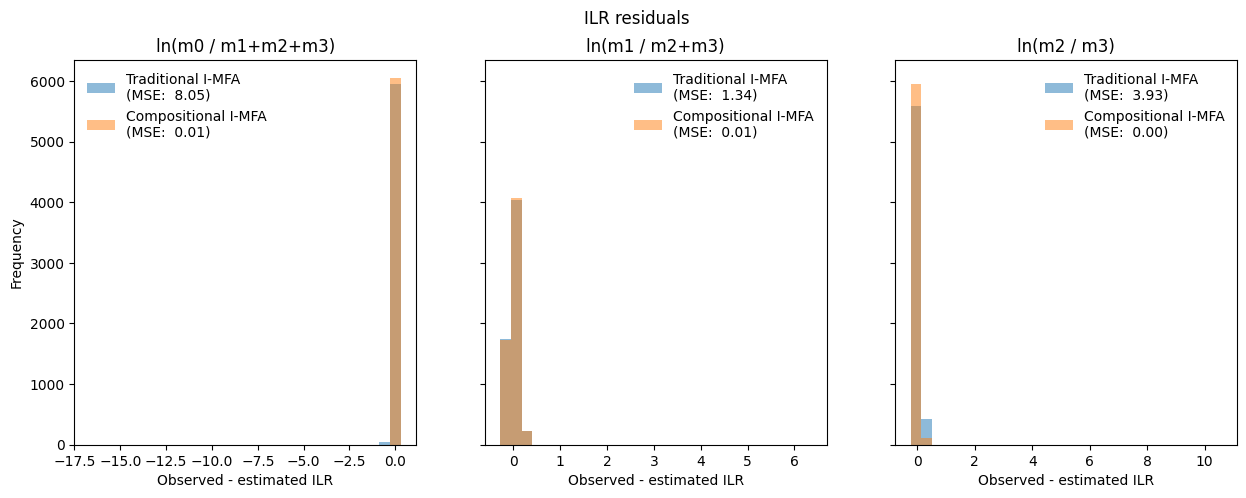

In [36]:
ratio_lhs = (f"m{i}" for i in range(3))
ratio_rhs = ("+".join([f"m{j}" for j in range(i+1, 4)]) for i in range(3))
labels = (f"ln({ratio_lhs_i} / {ratio_rhs_i})" for ratio_lhs_i, ratio_rhs_i in zip(ratio_lhs, ratio_rhs))


f, axes = plt.subplots(1, 3, figsize=[15, 5], sharey=True)

for (i, ax), label in zip(enumerate(axes), labels):
    resid_trad_i = ilr_resid_trad[:, :, i].flatten()
    resid_comp_i = ilr_resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.00185)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.998)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {ilr_mse_trad[i]: .2f})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE: {ilr_mse_ilr[i]: .2f})" 
    )
    ax.set(title=label, xlabel="Observed - estimated ILR")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
f.suptitle("ILR residuals");

**Figure caption** Traditional vs Compositional I-MFA flux estimates on a toy model. We fit traditional and compositional I-MFA to 1000 simulated datasets based on the toy model in [Antoniewicz reference]. The datasets were simulated assuming noise on pre-closure measurements with constant coefficient of variation based on a model of mass spectrometer intensity measurements (lognormal scale parameter 0.1, corresponding to approximately 2% worst error after closure to compositions).

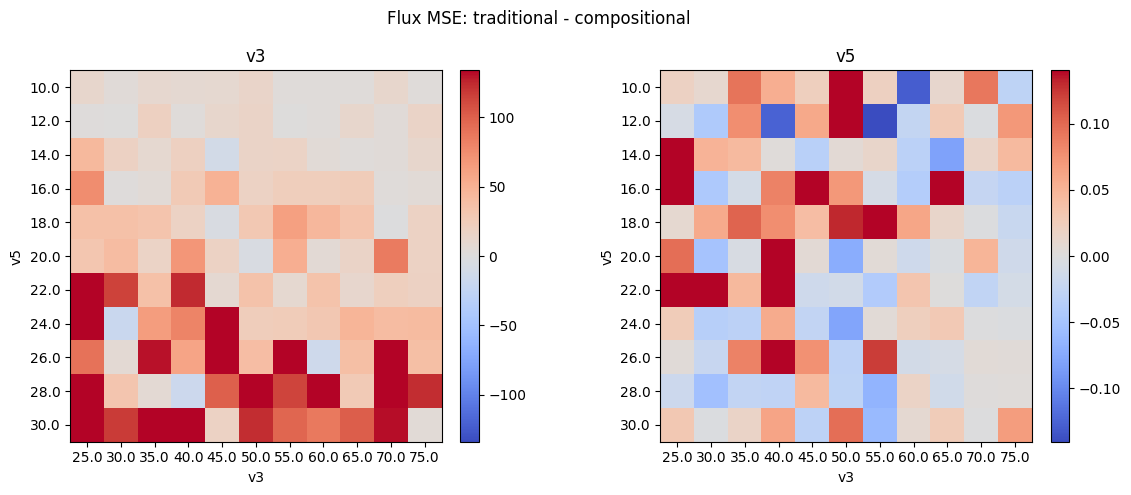

In [37]:
f, axes = plt.subplots(1, 2, figsize=[12, 5])
axes = axes.ravel()

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff = (resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1)

for i in range(2):
    halfrange = np.quantile(np.abs(diff[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=f"v{3+2*i}")
f.suptitle("Flux MSE: traditional - compositional")

f.tight_layout()

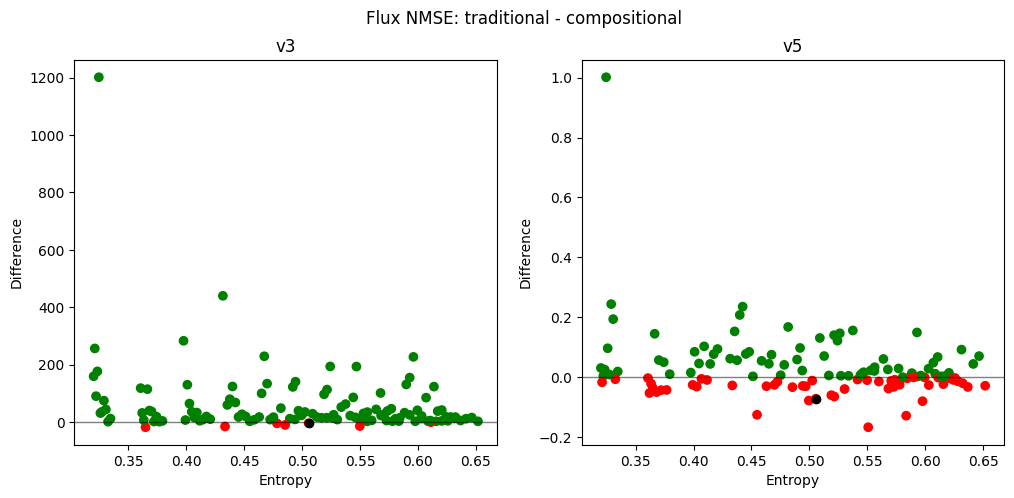

In [38]:
diff_flux = ((resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1))

f, axes = plt.subplots(1, 2, figsize=[12, 5])
axes = axes.ravel()
true_flux_index = 60
for i in range(2):
    y_values = diff_flux[:, i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(entropies, y_values, c=colors)
    axes[i].scatter(entropies[true_flux_index], y_values[true_flux_index], color="black", label="Reference flux")
    axes[i].axhline(0, color='black', lw=1, alpha=0.5)
    axes[i].set(xlabel="Entropy", ylabel="Difference", title=f"v{3+2*i}")
f.suptitle("Flux NMSE: traditional - compositional")
plt.show()


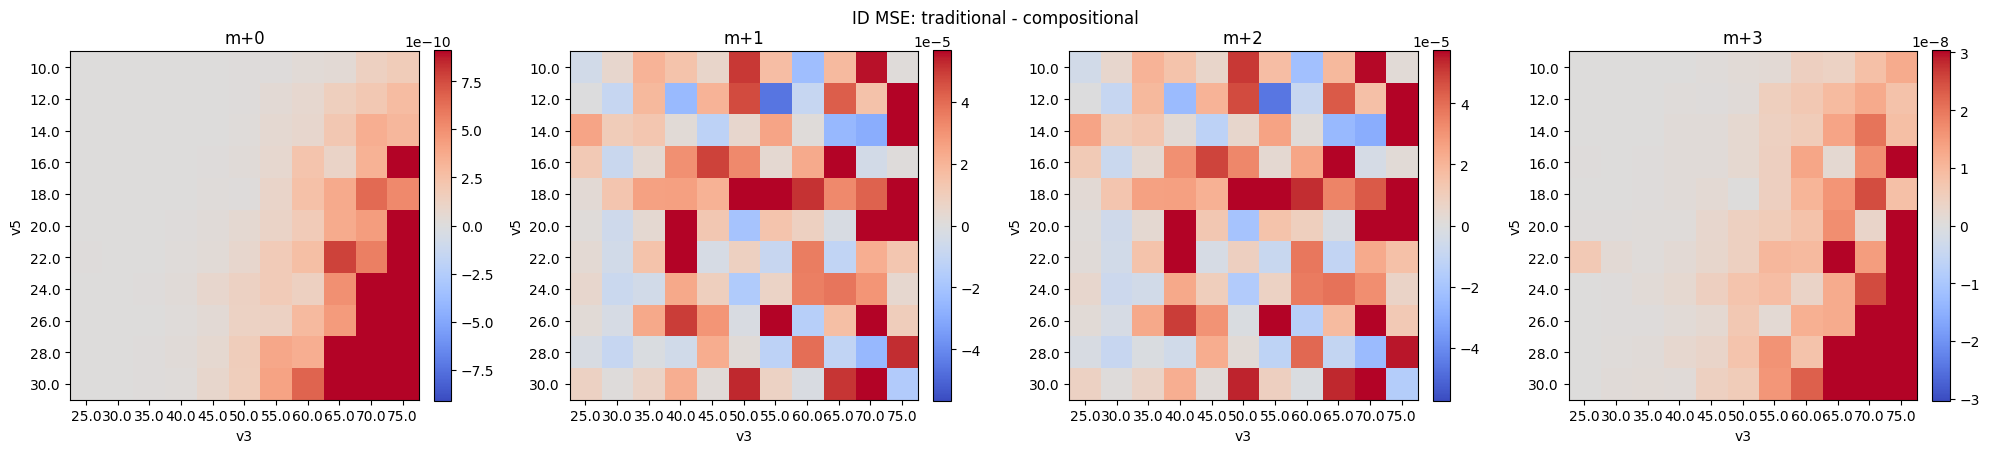

In [39]:
f, axes = plt.subplots(1, 4, figsize=[20, 8])
axes = axes.ravel()

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff_id = (id_resid_trad ** 2).mean(axis=1) - (id_resid_ilr ** 2).mean(axis=1)

for i in range(4):
    halfrange = np.quantile(np.abs(diff_id[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff_id[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=f"m+{i}")
f.suptitle("ID MSE: traditional - compositional", y=0.75);
f.tight_layout()

In [40]:
diff_id = ((id_resid_trad ** 2).mean(axis=1) - (id_resid_ilr ** 2).mean(axis=1))
# /((id_resid_trad ** 2).mean(axis=1))
gini_id = jnp.column_stack((gini_indices, diff_id))

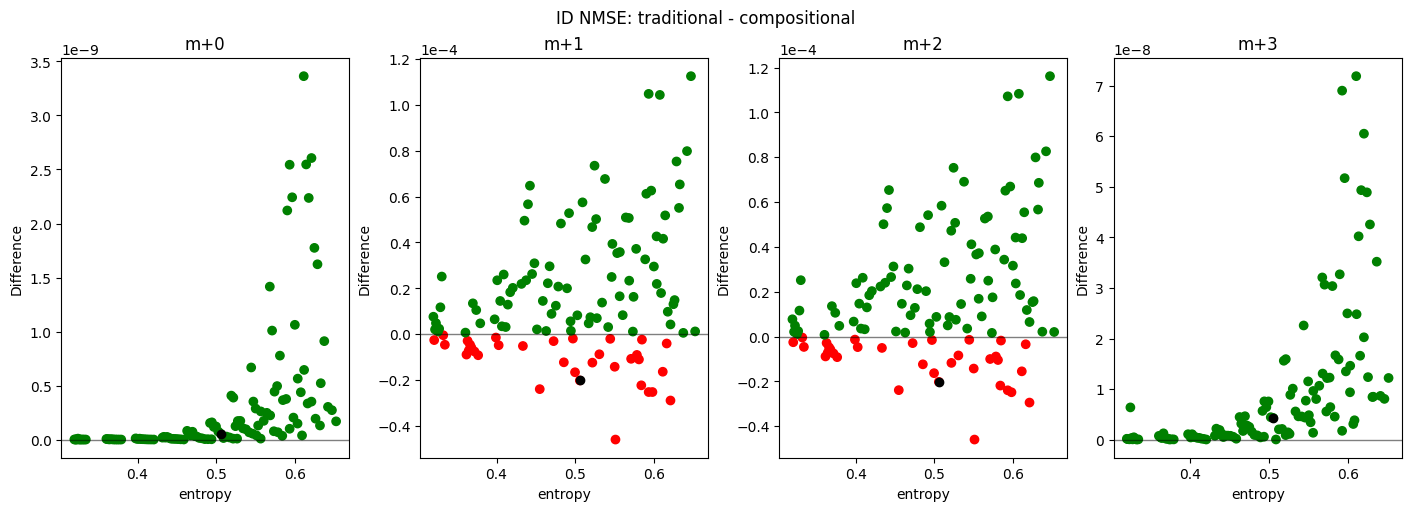

In [41]:
f, axes = plt.subplots(1, 4, figsize=[14, 5], layout="constrained")
axes = axes.ravel()

for (i, axes) in enumerate(axes):
    y_values = diff_id[:, i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes.scatter(entropies, y_values, c=colors)
    axes.scatter(entropies[true_flux_index], y_values[true_flux_index], color="black", label="Reference flux")
    axes.axhline(0, color='black', lw=1, alpha=0.5)
    axes.set(xlabel="entropy", ylabel="Difference", title=f"m+{i}")
    axes.ticklabel_format(scilimits=(-2,3))
f.suptitle("ID NMSE: traditional - compositional")
plt.show()

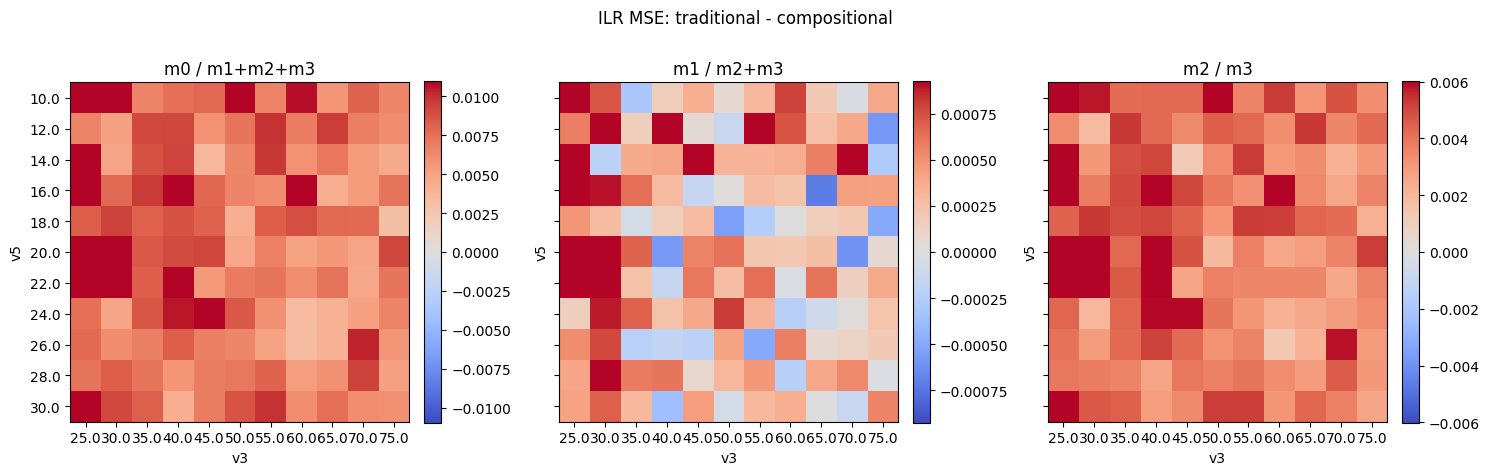

In [42]:
f, axes = plt.subplots(1, 3, sharey=True, figsize=[15, 5])

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff = (ilr_resid_trad ** 2).mean(axis=1) - (ilr_resid_ilr ** 2).mean(axis=1)

ratio_lhs = (f"m{i}" for i in range(3))
ratio_rhs = ("+".join([f"m{j}" for j in range(i+1, 4)]) for i in range(3))
labels = (f"{ratio_lhs_i} / {ratio_rhs_i}" for ratio_lhs_i, ratio_rhs_i in zip(ratio_lhs, ratio_rhs))


for i, label in enumerate(labels):
    halfrange = np.quantile(np.abs(diff[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=label)
f.suptitle("ILR MSE: traditional - compositional", y=0.96);
f.tight_layout()

**Figure caption** Traditional vs Compositional I-MFA isotopologue estimates on a toy model. Note that compositional I-MFA is far better than traditional I-MFA at estimating ratios that are sensitive to the low-abundance isotopologues m0 and m3.

# Confidence intervals with MC

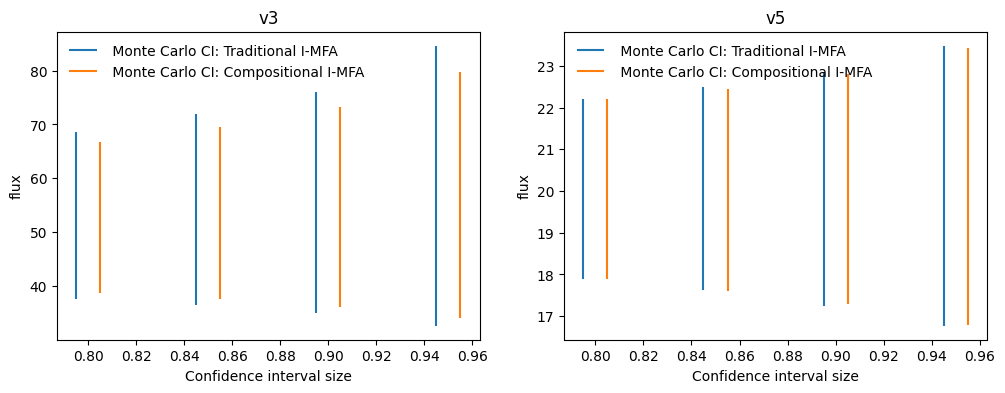

In [43]:
def get_ci_bounds(ci_size):
    low = (1.0 - ci_size) / 2
    high = 1.0 - low
    return low, high

IX_FREE_FLUXES = np.array([4,5])

with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    mc_estimated_fluxes = pickle.load(f)

mc_free_fluxes = {k: v[:, IX_FREE_FLUXES] for k, v in mc_estimated_fluxes.items()}
mc_free_fluxes["trad"].shape

N_BOUND = 4

plot_df_rows = []
ci_sizes = np.linspace(0.80, 0.95, N_BOUND)
for i, ci_size in enumerate(ci_sizes):
    row = {"ci_size": ci_size}
    qlow, qhigh = get_ci_bounds(ci_size)
    for model in ("trad", "ilr"):
        row[f"{model}_low_4"] = np.quantile(mc_estimated_fluxes[model][:, 4], qlow, axis=0)
        row[f"{model}_low_5"] = np.quantile(mc_estimated_fluxes[model][:, 5], qlow, axis=0)
        row[f"{model}_high_4"] = np.quantile(mc_estimated_fluxes[model][:, 4], qhigh, axis=0)
        row[f"{model}_high_5"] = np.quantile(mc_estimated_fluxes[model][:, 5], qhigh, axis=0)
    plot_df_rows.append(row)


plot_df = pl.DataFrame(plot_df_rows)
f, axes = plt.subplots(1, 2, figsize=[12, 4])
axes = axes.ravel()
for ax, flux_ix in zip(axes, (4, 5)):
    for offset, model, color in zip((-0.005, 0.005), ("trad", "ilr"), ("tab:blue", "tab:orange")):
        ax.vlines(
            plot_df["ci_size"] + offset, 
            plot_df[f"{model}_low_{flux_ix}"], 
            plot_df[f"{model}_high_{flux_ix}"], 
            color=color,
            label=" Monte Carlo CI: " + model.replace("ilr", "Compositional I-MFA").replace("trad", "Traditional I-MFA")
        )
    # ax.axhline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]: .2f})")
    ax.set(xlabel="Confidence interval size", ylabel="flux", title=f"v{(flux_ix-4)*2 + 3}")
    ax.legend(frameon=False, loc="upper left")

In [74]:
s1 = 123
s2 = 255
s3 = 919

In [79]:
print(estimated_fluxes_ci_reference["trad"][s2])

[[1.46734726e-01 6.46584568e+04]
 [5.64520496e+00 9.00750666e+01]
 [1.93892166e+01 3.09374946e+02]
 [1.00000000e+02 1.00000000e+02]
 [6.13829847e-03 2.94315378e+05]
 [5.64520496e+00 9.00750666e+01]]


In [78]:
estimated_fluxes_ci_reference["ilr"][s2]

Array([[ 21.02916312, 417.16558533],
       [ 16.12153886,  31.96472624],
       [ 54.89634913, 108.84486811],
       [100.        , 100.        ],
       [ 16.9452083 ,  90.05350957],
       [ 16.12153886,  31.96472624]], dtype=float64)

In [ ]:
import numpy as np
import jax.numpy as jnp
from functools import partial
import pypesto
import optimistix
from pypesto.result import OptimizerResult
import pypesto.profile as profile
import sys

# Ensure your custom module is findable
sys.path.insert(0, "../scripts")
import toy_network

# 1. Setup Data
sim_id = simulated_id[s1]
sim_ids = np.array([simulated_id[s1],simulated_id[s2],simulated_id[s3]])
sd = np.std(sim_ids, axis=0)
sd_all = np.std(simulated_id)
weights = 1/sd_all

# 2. Optimization with Optimistix
# Note: Ensure loss_trad signature is: loss_trad(params, args)
init_guess = jnp.array([100.0, 50.0])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result = optimistix.minimise(
    toy_network.loss_trad,
    y0=jnp.log(init_guess),
    args=(sim_ids, weights),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)


In [116]:
np.exp(opt_result.value)

array([45.78797432, 20.80883799])

In [126]:
# 3. Create pyPESTO Objective
# PyPESTO will call this function as objective(x)
def my_loss_function(x): 
    return toy_network.loss_trad(x, args=(sim_id, weights))[0] 

objective = pypesto.Objective(fun=my_loss_function)

# 4. Define Problem
problem = pypesto.Problem(
    objective=objective,
    lb=[-5] * 2, 
    ub=[5] * 2,  
    x_names=['v3', 'v5']
)

# 5. Manually inject the Optimistix result into pyPESTO
result_trad = pypesto.Result(problem=problem)
opt_result_manual = OptimizerResult(
    x=np.array(opt_result.value),        # Convert JAX to NumPy
    fval=float(opt_result.state.f_info.f),          # Cast JAX scalar to float
    id="optimistix_bfgs",
)
result_trad.optimize_result.append(opt_result_manual)

# 6. Profile Likelihood
# pyPESTO will now use Scipy to "walk" the likelihood surface
result_trad = profile.parameter_profile(
    problem=problem,
    result=result_trad,
    optimizer=pypesto.optimize.ScipyOptimizer(),
    filename=None
)


  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [09:30<00:00, 142.50s/it]


[<Axes: xlabel='v3', ylabel='Log-posterior ratio'>, <Axes: xlabel='v5'>]

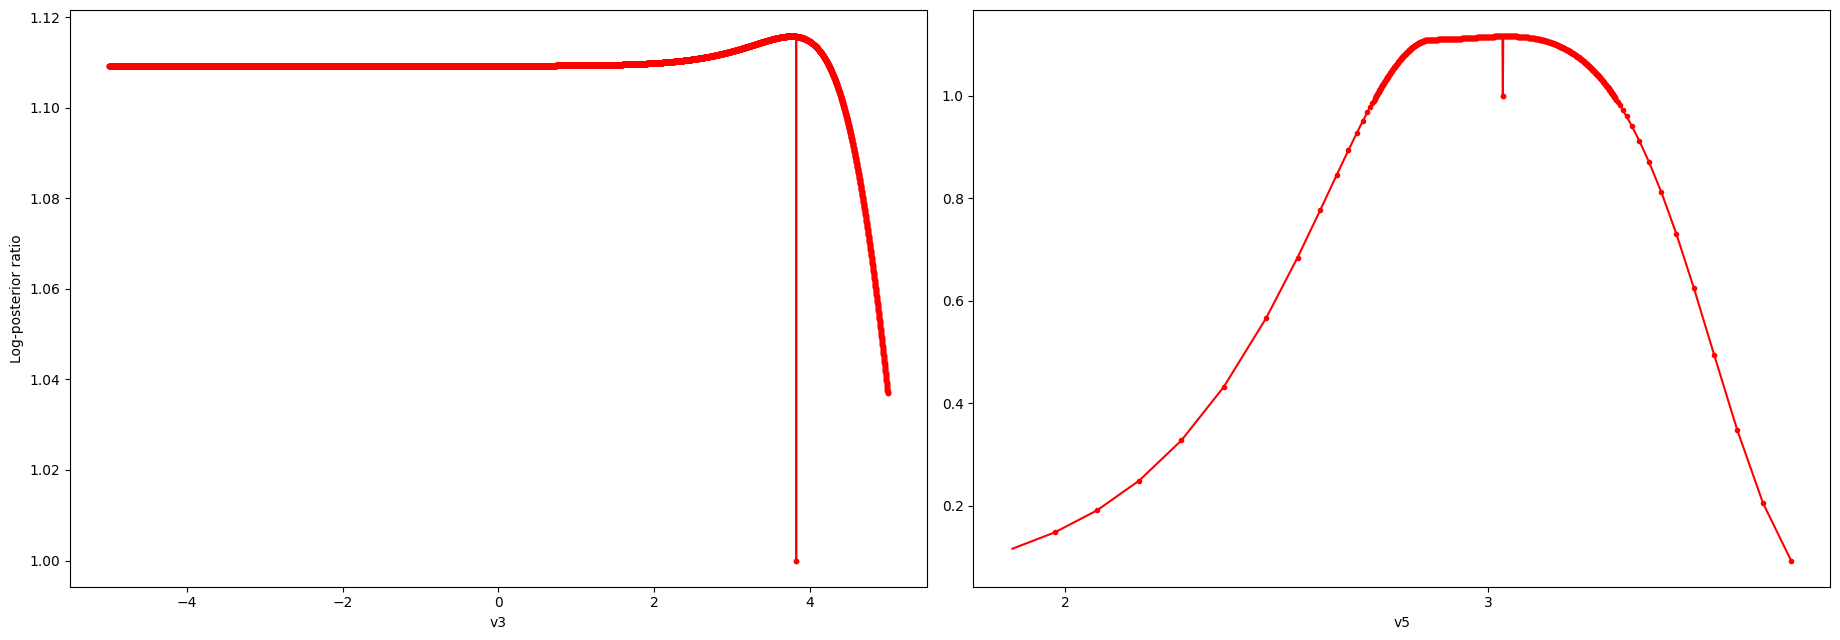

In [127]:
# Visualize the results (The "Likelihood Profile")
pypesto.visualize.profiles(result_trad, show_bounds=False)

In [119]:
result_trad.profile_result.get_profiler_result(0)["x_path"][0] = np.exp(result_trad.profile_result.get_profiler_result(0)["x_path"][0])
result_trad.profile_result.get_profiler_result(1)["x_path"][1] = np.exp(result_trad.profile_result.get_profiler_result(1)["x_path"][1])

[<Axes: xlabel='v3', ylabel='Log-posterior ratio'>, <Axes: xlabel='v5'>]

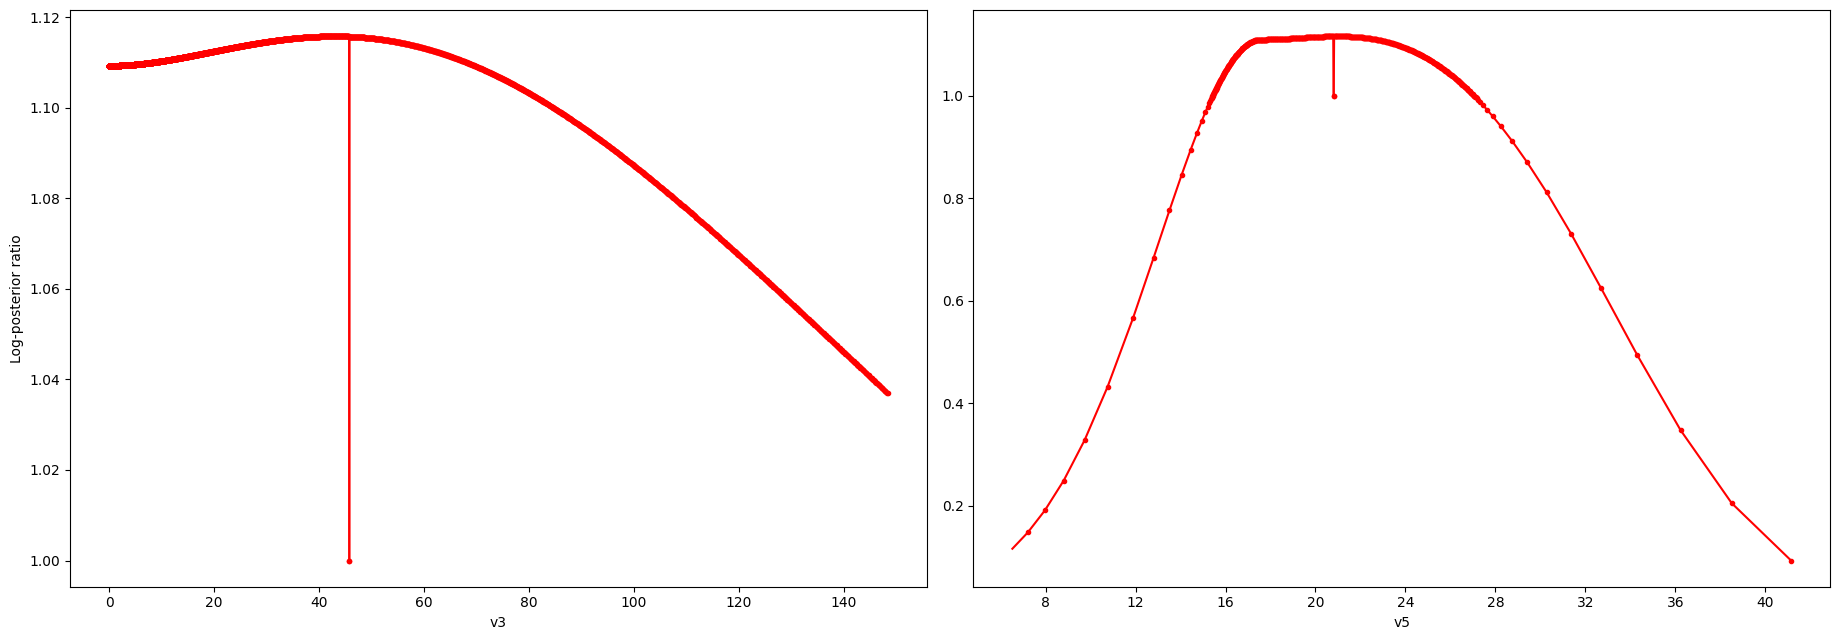

In [120]:
pypesto.visualize.profiles(result_trad)

In [63]:
np.std(ordered_ilr_func(simulated_id), axis=0)

Array([0.09959654, 0.10109038, 0.10162933], dtype=float64)

In [64]:
sd_ilr = np.array([0.09959654, 0.10109038, 0.10162933])
sim_ilr = ordered_ilr_func(simulated_id[1])
print(sim_ilr)

[-5.57354523  3.54440406  3.69055311]


In [ ]:
sim_id = simulated_id[s1]
sim_ids = np.array([simulated_id[s1],simulated_id[s2],simulated_id[s3]])
sd = np.std(sim_ids, axis=0)
weights = 1/sd

In [68]:
import numpy as np
import jax.numpy as jnp
from functools import partial
import pypesto
import optimistix
from pypesto.result import OptimizerResult
import pypesto.profile as profile
import sys
import scipy as sp

import pypesto.profile as profile

# Ensure your custom module is findable
sys.path.insert(0, "../scripts")
import toy_network

# 1. Setup Data
sd = np.array([0.09959654, 0.10109038, 0.10162933])
sim_id = simulated_id[1]
weights = 1/sd

# 2. Optimization with Optimistix
# Note: Ensure loss_trad signature is: loss_trad(params, args)
init_guess = jnp.array([10.0, 10.0])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result = optimistix.minimise(
    toy_network.loss_ilr,
    y0=jnp.log(init_guess),
    args=(sim_id, weights),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

# 3. Create pyPESTO Objective
# PyPESTO will call this function as objective(x)
def my_loss_function(x): 
    return toy_network.loss_ilr(x, args=(sim_id, weights))[0] 

objective = pypesto.Objective(fun=my_loss_function)

# 4. Define Problem
problem = pypesto.Problem(
    objective=objective,
    lb=[-6] * 2, 
    ub=[6] * 2,  
    x_names=['v3', 'v5']
)

# 5. Manually inject the Optimistix result into pyPESTO
result_ilr = pypesto.Result(problem=problem)
opt_result_manual = OptimizerResult(
    x=np.array(opt_result.value),        # Convert JAX to NumPy
    fval=float(opt_result.state.f_info.f),          # Cast JAX scalar to float
    id="optimistix_bfgs",
)
result_ilr.optimize_result.append(opt_result_manual)

options = profile.ProfileOptions(
    ratio_min=np.exp(-sp.stats.chi2.ppf(0.95, 1) / 2)
)

# 6. Profile Likelihood
# pyPESTO will now use Scipy to "walk" the likelihood surface
result_ilr = profile.parameter_profile(
    problem=problem,
    result=result_ilr,
    optimizer=pypesto.optimize.ScipyOptimizer(method="L-BFGS-B"),
)


  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:15<00:00,  3.80s/it]


[<Axes: xlabel='v3', ylabel='Log-posterior ratio'>, <Axes: xlabel='v5'>]

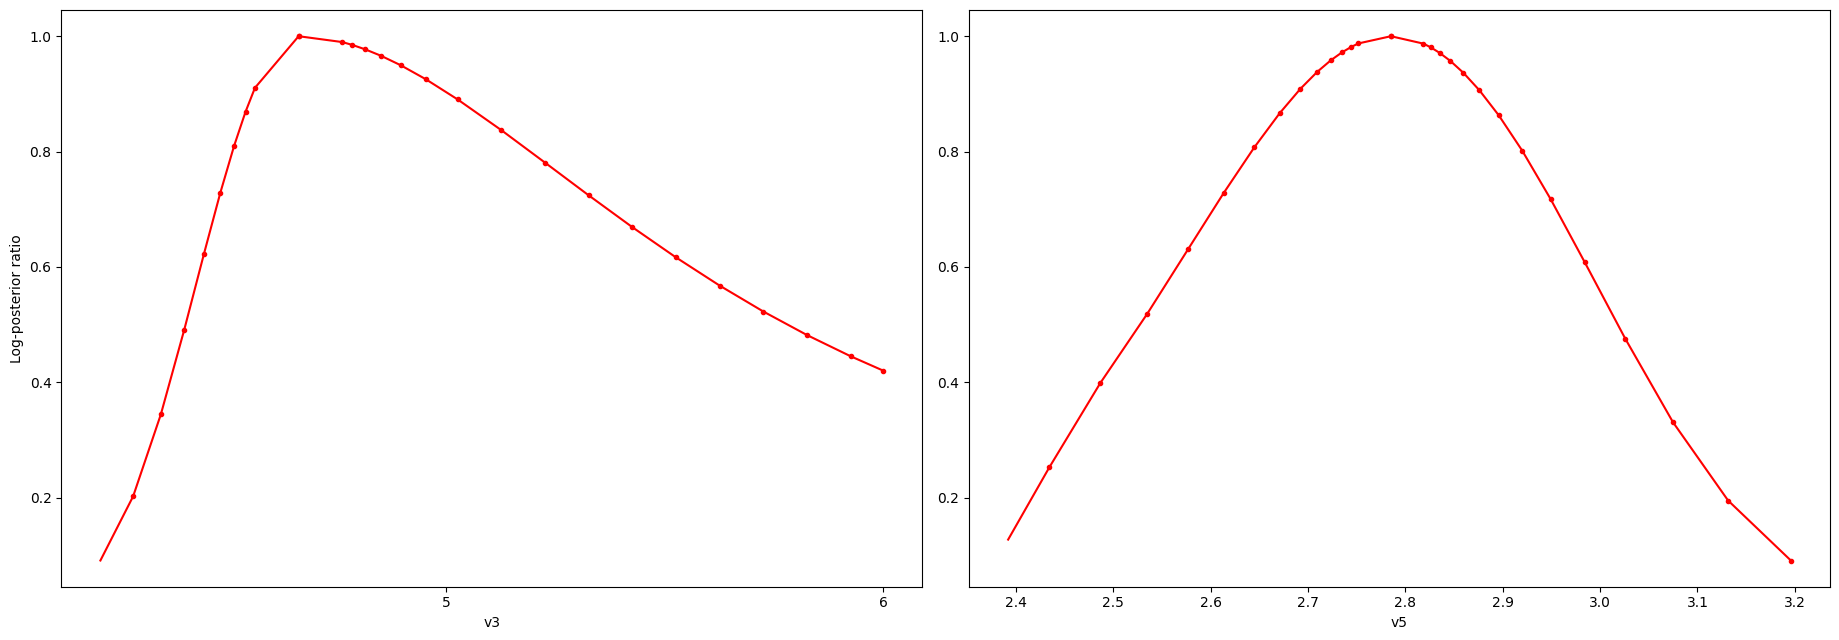

In [69]:
pypesto.visualize.profiles(result_ilr, show_bounds=False)

In [70]:
result_ilr.profile_result.get_profiler_result(0)["x_path"][0] = np.exp(result_ilr.profile_result.get_profiler_result(0)["x_path"][0])
result_ilr.profile_result.get_profiler_result(1)["x_path"][1] = np.exp(result_ilr.profile_result.get_profiler_result(1)["x_path"][1])

[<Axes: xlabel='v3', ylabel='Log-posterior ratio'>, <Axes: xlabel='v5'>]

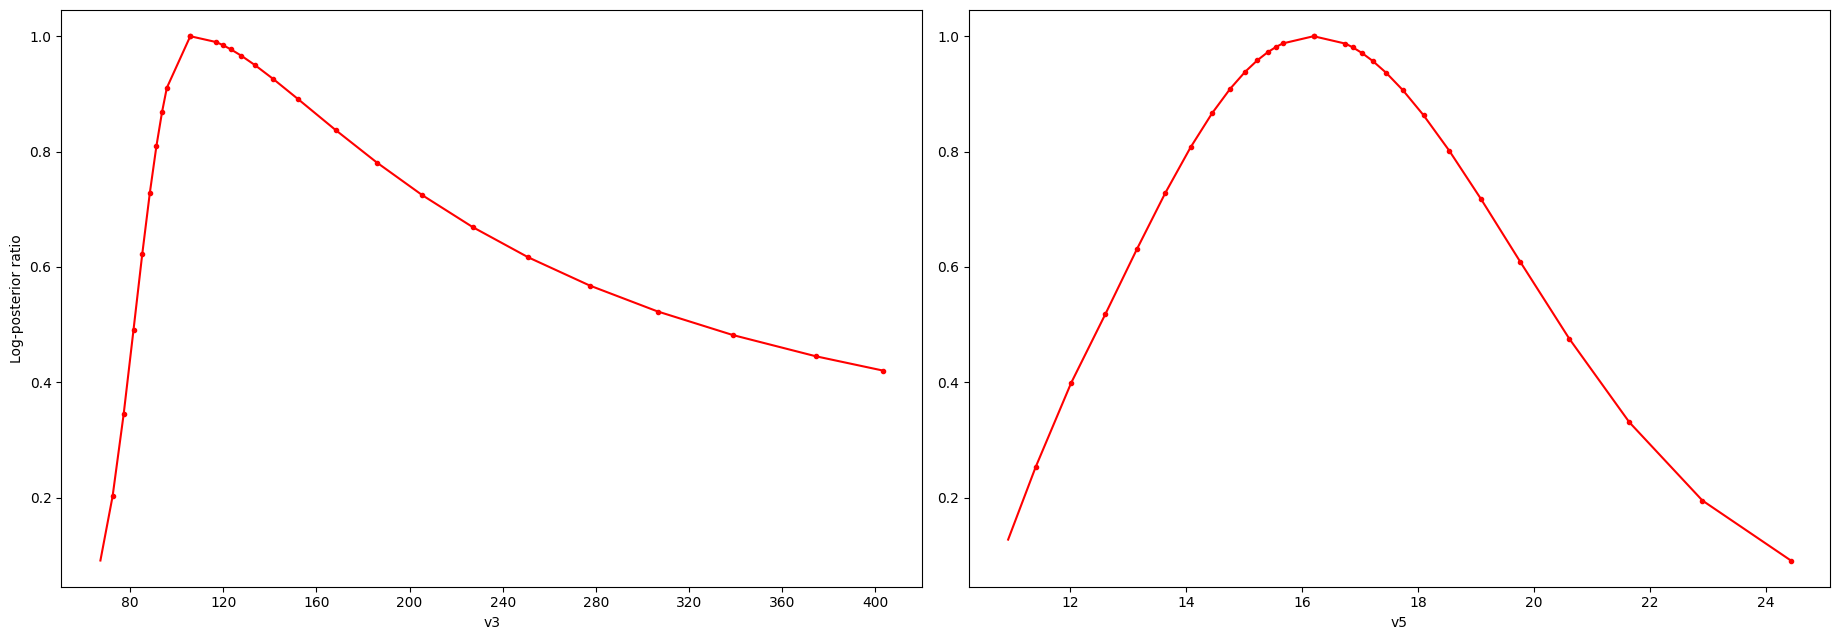

In [71]:
pypesto.visualize.profiles(result_ilr)

Simulate 3 experiment data - closue((intensity~lognorm)) 
- Estimate fluxes - 1
- profile likelihood - 1
- hessian - 1

draw 10000 sample - based on mean(3 simulated experiment)
